In [4]:
import sys
import cv2
import numpy as np
from matplotlib import pyplot as plt

import os
print(os.getcwd()) # Check the current path

# Add SDK path
sys.path.append("/home/z3/qvc_ws/MvImport")
from MvCameraControl_class import *

print("Libraries loaded successfully.")

/home/z3/qvc_ws
Libraries loaded successfully.


Found 1 camera(s).
Acquired image size: (2048, 3072)


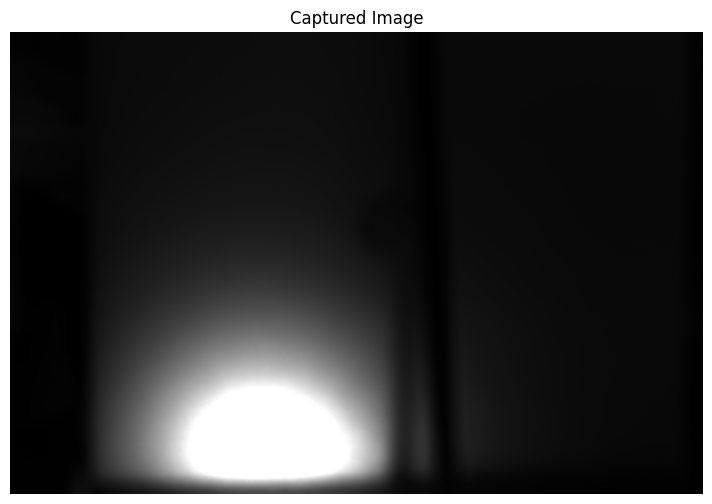

Camera released.


In [6]:
# 1. Enumerate devices
deviceList = MV_CC_DEVICE_INFO_LIST()
ret = MvCamera.MV_CC_EnumDevices(MV_GIGE_DEVICE | MV_USB_DEVICE, deviceList)

if deviceList.nDeviceNum == 0:
    print("No camera found, please check network cable and IP configuration!")
else:
    print(f"Found {deviceList.nDeviceNum} camera(s).")
    
    # 2. Open the first camera
    stDeviceList = cast(deviceList.pDeviceInfo[0], POINTER(MV_CC_DEVICE_INFO)).contents
    cam = MvCamera()
    cam.MV_CC_CreateHandle(stDeviceList)
    
    # 3. Set heartbeat timeout to 3 seconds to prevent abnormal program exit from causing a 60-second lock
    cam.MV_CC_SetIntValue("GevHeartbeatTimeout", 1400)
    ret = cam.MV_CC_OpenDevice(MV_ACCESS_Exclusive, 0)

    # Set exposure to 2000 microseconds (adjust this number until it looks right)
    cam.MV_CC_SetFloatValue("ExposureTime", 2000.0) 
    
    if ret != 0:
        print(f"Open device failed! Error code: {ret}")
    else:
        # 4. Set continuous mode and start grabbing
        cam.MV_CC_SetEnumValue("TriggerMode", MV_TRIGGER_MODE_OFF)
        cam.MV_CC_StartGrabbing()
        
        # 5. Grab one frame
        stParam = MVCC_INTVALUE()
        cam.MV_CC_GetIntValue("PayloadSize", stParam)
        payload_size = stParam.nCurValue
        data_buf = (c_ubyte * payload_size)()
        stFrameInfo = MV_FRAME_OUT_INFO_EX()
        
        ret = cam.MV_CC_GetOneFrameTimeout(data_buf, payload_size, stFrameInfo, 1000)
        if ret == 0:
            # Convert to numpy array
            image = np.frombuffer(data_buf, dtype=np.uint8, count=stFrameInfo.nFrameLen)
            image = image.reshape((stFrameInfo.nHeight, stFrameInfo.nWidth))
            print(f"Acquired image size: {image.shape}")
            
            # Save the image
            cv2.imwrite("jupyter_capture.png", image)
            
            # 6. Display in Notebook
            plt.figure(figsize=(10, 6))
            plt.imshow(image, cmap='gray')
            plt.title("Captured Image")
            plt.axis('off')
            plt.show()
        else:
            print(f"Frame grab failed! Error code: {ret}")
        
        # 7. Cleanup and release the camera
        cam.MV_CC_StopGrabbing()
        cam.MV_CC_CloseDevice()
        cam.MV_CC_DestroyHandle()
        print("Camera released.")

In [8]:
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
from ctypes import cast, POINTER

sys.path.append("/home/z3/qvc_ws/MvImport")
from MvCameraControl_class import *

# 1. Enumerate and Open
deviceList = MV_CC_DEVICE_INFO_LIST()
ret = MvCamera.MV_CC_EnumDevices(MV_GIGE_DEVICE | MV_USB_DEVICE, deviceList)

if deviceList.nDeviceNum == 0:
    print("No camera found.")
else:
    stDeviceList = cast(deviceList.pDeviceInfo[0], POINTER(MV_CC_DEVICE_INFO)).contents
    cam = MvCamera()
    cam.MV_CC_CreateHandle(stDeviceList)
    
    # Open the camera
    cam.MV_CC_OpenDevice(MV_ACCESS_Exclusive, 0)
    
    # CRITICAL: Limit packet size for USB adapter
    cam.MV_CC_SetIntValue("GevSCPSPacketSize", 1400) 
    
    # --- FIX THE FLICKERING AND BRIGHTNESS ---
    # 1. Turn off Auto Exposure (0 = Off, 1 = Once, 2 = Continuous)
    cam.MV_CC_SetEnumValue("ExposureAuto", 0) 
    
    # 2. Turn off Auto Gain
    cam.MV_CC_SetEnumValue("GainAuto", 0) 
    
    # 3. Set Exposure Time MUCH lower (try 100.0, 50.0, or 20.0)
    cam.MV_CC_SetFloatValue("ExposureTime", 100.0) 
    # -----------------------------------------
    
    # Start continuous grabbing
    cam.MV_CC_SetEnumValue("TriggerMode", MV_TRIGGER_MODE_OFF)
    cam.MV_CC_StartGrabbing()

    # Get payload size
    stParam = MVCC_INTVALUE()
    cam.MV_CC_GetIntValue("PayloadSize", stParam)
    payload_size = stParam.nCurValue
    data_buf = (c_ubyte * payload_size)()
    stFrameInfo = MV_FRAME_OUT_INFO_EX()

    print("Starting live stream... (Click 'Stop' / Interrupt Kernel to end)")

    try:
        while True:
            ret = cam.MV_CC_GetOneFrameTimeout(data_buf, payload_size, stFrameInfo, 1000)
            if ret == 0:
                # Convert raw data to numpy array
                image = np.frombuffer(data_buf, dtype=np.uint8, count=stFrameInfo.nFrameLen)
                image = image.reshape((stFrameInfo.nHeight, stFrameInfo.nWidth))
                
                # --- YOUR QUALITY INSPECTION LOGIC HERE ---
                # For now, let's just convert it to color so we can draw on it later
                display_img = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
                
                # Display
                clear_output(wait=True) # Clears previous frame for smooth video
                plt.figure(figsize=(8, 6))
                plt.imshow(display_img)
                plt.title("Live Camera Feed")
                plt.axis('off')
                plt.show()
                
            else:
                print(f"Frame grab failed! Error code: {ret}")
                break

    except KeyboardInterrupt:
        print("Stream stopped by user.")

    finally:
        # Cleanup
        cam.MV_CC_StopGrabbing()
        cam.MV_CC_CloseDevice()
        cam.MV_CC_DestroyHandle()
        print("Camera released.")

Stream stopped by user.
Camera released.


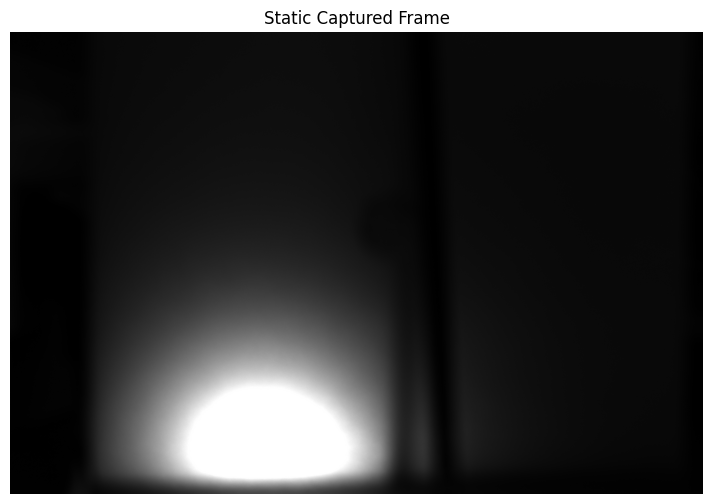

Image shape: (2048, 3072)


In [10]:
import matplotlib.pyplot as plt

# 1. Take out the latest image we just captured and saved
img = cv2.imread("jupyter_capture.png", cv2.IMREAD_GRAYSCALE)

# 2. Display it using matplotlib (this will show a clear picture and will not disappear)
plt.figure(figsize=(10, 6))
plt.imshow(img, cmap='gray')
plt.title("Static Captured Frame")
plt.axis('off')
plt.show()

# 3. Check the image dimensions
print(f"Image shape: {img.shape}")

In [11]:
import sys
sys.path.append("/home/z3/qvc_ws/MvImport")
from MvCameraControl_class import *
import ctypes

# 1. Enumerate devices to find the camera
deviceList = MV_CC_DEVICE_INFO_LIST()
ret = MvCamera.MV_CC_EnumDevices(MV_GIGE_DEVICE | MV_USB_DEVICE, deviceList)

if deviceList.nDeviceNum == 0:
    print("No camera found")
else:
    # 2. Get the camera information (the first one)
    stDeviceList = cast(deviceList.pDeviceInfo[0], POINTER(MV_CC_DEVICE_INFO)).contents
    
    # 3. Create handle
    cam = MvCamera()
    cam.MV_CC_CreateHandle(stDeviceList)
    
    # 4. Forcefully set the IP to 192.168.1.64
    # Convert IP to hexadecimal integer
    ip_str = "192.168.1.64"
    ip_parts = [int(x) for x in ip_str.split('.')]
    ip_hex = (ip_parts[0] << 24) + (ip_parts[1] << 16) + (ip_parts[2] << 8) + ip_parts[3]
    
    # Subnet mask 255.255.255.0
    mask_hex = (255 << 24) + (255 << 16) + (255 << 8) + 0
    # Gateway 192.168.1.1
    gw_hex = (192 << 24) + (168 << 16) + (1 << 8) + 1
    
    ret = cam.MV_GIGE_ForceIpEx(ip_hex, mask_hex, gw_hex)
    if ret == 0:
        print(f"IP force change successful! Camera new IP: {ip_str}")
    else:
        print(f"IP force change failed, error code: {ret}")
    
    # 5. Destroy handle
    cam.MV_CC_DestroyHandle()

IP force change successful! Camera new IP: 192.168.1.64


In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. Load the image
# ==========================================
img = cv2.imread("jupyter_capture.png", cv2.IMREAD_GRAYSCALE)
if img is None:
    print("Error: Could not load jupyter_capture.png. Please make sure you captured an image.")
else:
    # ==========================================
    # 2. Image Preprocessing
    # ==========================================
    # Gaussian blur to reduce noise
    blurred = cv2.GaussianBlur(img, (5, 5), 0)
    
    # Adaptive thresholding (works better than global thresholding for uneven lighting)
    # Note: You might need to invert the threshold (cv2.THRESH_BINARY_INV) if the pencil is darker than the background.
    # Assuming the background is bright and the pencil is dark:
    thresh = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
                                   cv2.THRESH_BINARY_INV, 21, 10)

    # ==========================================
    # 3. Find Contours
    # ==========================================
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours:
        print("No contours found. Try adjusting the threshold parameters.")
    else:
        # Find the largest contour (assuming the pencil is the largest object)
        c = max(contours, key=cv2.contourArea)
        
        # Get the minimum bounding rectangle
        rect = cv2.minAreaRect(c)
        box = cv2.boxPoints(rect)
        box = np.int32(box)
        
        # Extract width and height from the rectangle
        # rect[1] returns (width, height)
        (width, height) = rect[1]
        
        # The width of the pencil will be the smaller of the two dimensions
        pencil_width_pixels = min(width, height)
        
        # ==========================================
        # 4. Calculate Real-World Width (Requires Calibration)
        # ==========================================
        # PLACEHOLDER: Replace this with your actual calibration scale (mm/pixel)
        # If you haven't calibrated yet, this is just a dummy value.
        pixel_scale_mm = 0.05  # Example: 0.05 mm per pixel
        
        real_width_mm = pencil_width_pixels * pixel_scale_mm
        
        print(f"Measured width in pixels: {pencil_width_pixels:.2f} px")
        print(f"Estimated real width: {real_width_mm:.3f} mm (using scale {pixel_scale_mm} mm/px)")

        # ==========================================
        # 5. Draw and Display the Result
        # ==========================================
        result_img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        cv2.drawContours(result_img, [box], 0, (0, 0, 255), 2) # Draw bounding box in red
        
        # Draw the width line
        # We draw a line between the midpoints of the two long edges
        # This is a simplified visualization
        cv2.putText(result_img, f"{pencil_width_pixels:.1f} px", 
                    (int(rect[0][0]), int(rect[0][1])), 
                    cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

        plt.figure(figsize=(12, 8))
        plt.subplot(1, 2, 1)
        plt.imshow(thresh, cmap='gray')
        plt.title("Thresholded Image")
        
        plt.subplot(1, 2, 2)
        plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
        plt.title(f"Detected Pencil (Width: {pencil_width_pixels:.1f} px)")
        plt.show()

No contours found. Try adjusting the threshold parameters.


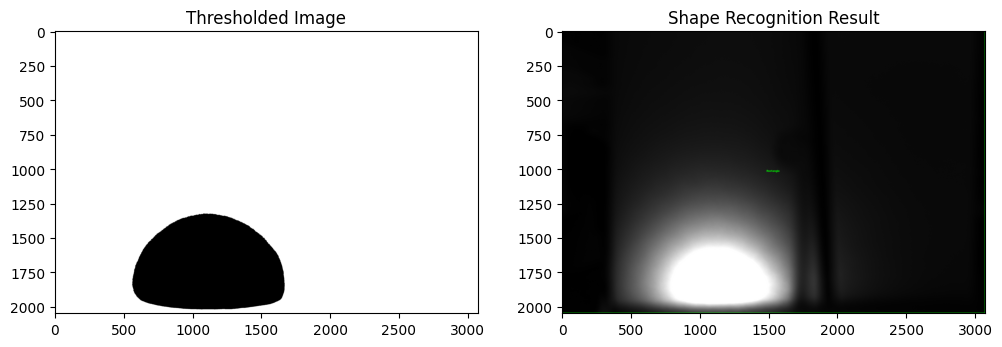

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the latest image (make sure you have re-run the camera capture code)
img = cv2.imread("jupyter_capture.png", cv2.IMREAD_GRAYSCALE)

# 2. Preprocessing
blurred = cv2.GaussianBlur(img, (5, 5), 0)
# Use Otsu's binarization (automatically finds the best threshold, suitable for changing objects)
_, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 3. Find contours
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Create a color image for drawing results
result_img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

for c in contours:
    # Ignore small noise contours
    area = cv2.contourArea(c)
    if area < 1000:
        continue
        
    # 4. Contour approximation (core step)
    # perimeter is the contour perimeter; 0.04 is the approximation precision (smaller = more precise)
    peri = cv2.arcLength(c, True)
    approx = cv2.approxPolyDP(c, 0.04 * peri, True)
    
    # 5. Determine shape based on vertex count
    vertices = len(approx)
    
    # Get the center point for writing text
    M = cv2.moments(c)
    if M["m00"] != 0:
        cX = int(M["m10"] / M["m00"])
        cY = int(M["m01"] / M["m00"])
    else:
        cX, cY = 0, 0

    shape_name = "Unknown"
    
    if vertices == 3:
        shape_name = "Triangle"
        color = (0, 0, 255) # Red
    elif vertices == 4:
        # Further distinguish square from rectangle
        (x, y, w, h) = cv2.boundingRect(approx)
        aspectRatio = w / float(h)
        if 0.95 <= aspectRatio <= 1.05:
            shape_name = "Square"
        else:
            shape_name = "Rectangle"
        color = (0, 255, 0) # Green
    else:
        # Use circularity to distinguish circle from other polygons
        # Circularity = 4 * pi * Area / (Perimeter^2), perfect circle is 1
        circularity = 4 * np.pi * area / (peri * peri)
        if circularity > 0.8:
            shape_name = "Circle"
            color = (255, 0, 0) # Blue
        else:
            shape_name = f"Polygon ({vertices} sides)"
            color = (255, 255, 0) # Cyan
            
    # 6. Draw results
    cv2.drawContours(result_img, [approx], -1, color, 2)
    cv2.putText(result_img, shape_name, (cX - 50, cY), 
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)

# 7. Display
plt.figure(figsize=(12, 8))
plt.subplot(1, 2, 1)
plt.imshow(thresh, cmap='gray')
plt.title("Thresholded Image")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result_img, cv2.COLOR_BGR2RGB))
plt.title("Shape Recognition Result")
plt.show()